# 🎲 Notebook 1 — Monte Carlo Warm-Up
**Monte Carlo for Polymer Reaction Engineering · a hands-on mini-course**

> Never used Monte Carlo before? Start here. No polymers yet — just dice, darts and coins.

| | |
|---|---|
| ⏱ Time | ~20 min |
| 🎯 You will learn | the **4 tricks** that every algorithm in the course is built from |
| 📖 Companion book | *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* |

**How to use this notebook:** in Colab, click **Runtime → Run all**, then read from top to bottom. Change the numbers in any cell and run it again — that's the whole point.

### 🗺️ The course
The book (and this course) uses two families of Monte Carlo models:
- **Steady state Monte Carlo** (book Ch. 3): the probabilities of all events stay **constant**, so chains are built one after another.
- **Dynamic Monte Carlo** (book Ch. 4, Gillespie's method): the reaction rates **change with time**, so the simulation follows every event on a clock.

| # | Notebook | Type |
|---|---|---|
| 1 | **Monte Carlo warm-up** ← *you are here* | basics |
| 2 | Chain growth & molecular weight distributions | steady state |
| 3 | Copolymers & composition | steady state |
| 4 | Long-chain branching | steady state |
| 5 | Step growth & gelation | sequential sampling + dynamic |
| 6 | Dynamic Monte Carlo: Gillespie's method | dynamic |
| 7 | Dynamic Monte Carlo: ATRP & degradation (simplified) | dynamic |
| 8 | Case Study 3.1: styrene free-radical polymerization | steady state |
| 9 | Case Study 3.2: styrene/MMA copolymerization | steady state |
| 10 | Case study: control volume in Gillespie simulations (Sec. 4.6) | dynamic |

## What *is* Monte Carlo?
- Use **random numbers** to imitate a process that has chance in it.
- Repeat it **many times**.
- **Count** what happened → averages and distributions.

Polymerization is full of chance: *will this chain add one more monomer, or stop?* Monte Carlo lets us answer by simply... asking the dice, a million times.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)                     # same "random" numbers every run → reproducible
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})

## 1 · The random number `Rnd`
Everything starts with a number picked uniformly between 0 and 1. In the book's algorithms it is written `Rnd ← random(0,1)`.

[0.639, 0.025, 0.275, 0.223, 0.736, 0.677, 0.892, 0.087]


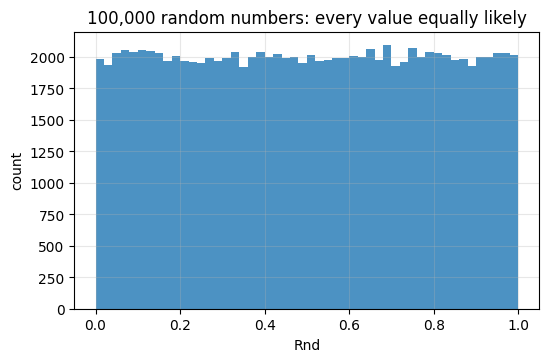

In [2]:
print([round(random.random(), 3) for _ in range(8)])

rnd = [random.random() for _ in range(100_000)]
plt.hist(rnd, bins=50, color="tab:blue", alpha=0.8)
plt.title("100,000 random numbers: every value equally likely")
plt.xlabel("Rnd"); plt.ylabel("count"); plt.show()

## 2 · Trick #1 — "Does it happen?"  `if Rnd ≤ P`
An event with probability `P` happens when `Rnd ≤ P`. This **single line** is the heart of chapters on chain growth.

Example: a coin with `P = 0.5`. Watch the fraction of heads settle down as we flip more (the *law of large numbers*).

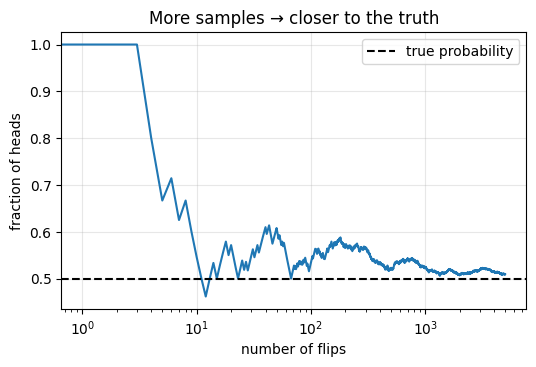

In [3]:
P = 0.5
heads, running = 0, []
for i in range(1, 5001):
    if random.random() <= P:      # ← Trick #1
        heads += 1
    running.append(heads / i)

plt.plot(running)
plt.axhline(P, color="k", ls="--", label="true probability")
plt.xscale("log"); plt.xlabel("number of flips"); plt.ylabel("fraction of heads")
plt.title("More samples → closer to the truth"); plt.legend(); plt.show()

## 3 · Trick #2 — estimate a number by counting (darts for π)
Throw darts at a 1×1 square. The fraction landing inside the quarter circle is π/4.

**Key lesson:** the error shrinks like **1/√N**. 100× more samples → only 10× more accurate. You will see this "noise" in every distribution later.

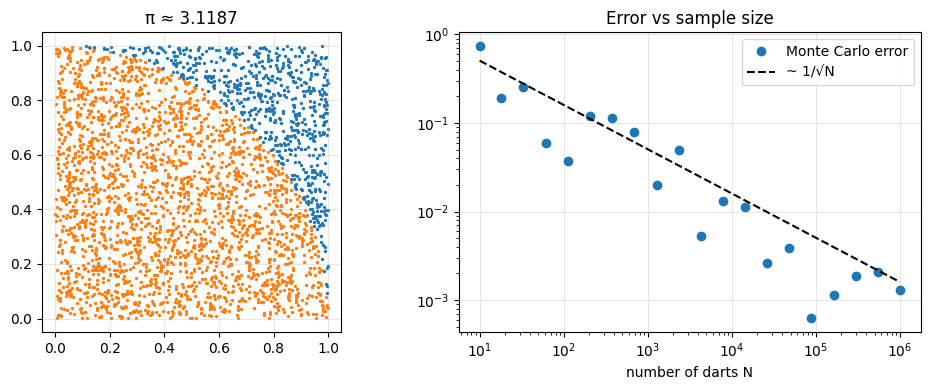

In [4]:
N = 3000
x = np.array([random.random() for _ in range(N)])
y = np.array([random.random() for _ in range(N)])
inside = x**2 + y**2 <= 1

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(x[inside], y[inside], s=2, c="tab:orange")
ax[0].scatter(x[~inside], y[~inside], s=2, c="tab:blue")
ax[0].set_aspect("equal"); ax[0].set_title(f"π ≈ {4*inside.mean():.4f}")

Ns = np.logspace(1, 6, 20).astype(int)
errors = [abs(4*np.mean(np.random.rand(k)**2 + np.random.rand(k)**2 <= 1) - np.pi) for k in Ns]
ax[1].loglog(Ns, errors, "o", label="Monte Carlo error")
ax[1].loglog(Ns, 1.6/np.sqrt(Ns), "k--", label="~ 1/√N")
ax[1].set_xlabel("number of darts N"); ax[1].legend(); ax[1].set_title("Error vs sample size")
plt.tight_layout(); plt.show()

## 4 · Trick #3 — "Which one happens?" (the roulette wheel)
Several possible events, each with a weight (a rate). Line them up end-to-end, throw `Rnd × total`, and see where it lands.

This is exactly the *"Find reaction j such that Σ…"* line in every Gillespie algorithm of the book. Here: a simple example where propagation is much more likely than termination.

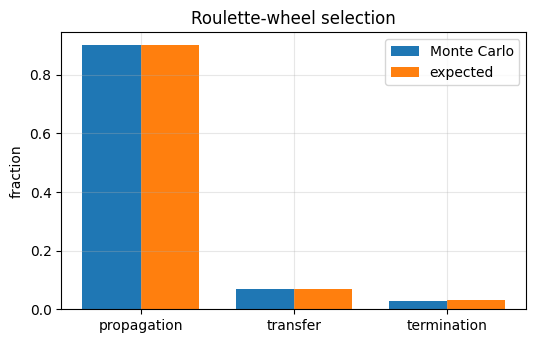

In [5]:
events = ["propagation", "transfer", "termination"]
rates  = np.array([90.0, 7.0, 3.0])         # any positive numbers (relative weights)

def pick_event(rates):
    cum = np.cumsum(rates)
    r = random.random() * cum[-1]           # ← Rnd × R_total
    return int(np.searchsorted(cum, r))     # first j with cumulative sum ≥ r

counts = np.zeros(len(rates))
for _ in range(20_000):
    counts[pick_event(rates)] += 1

w = 0.38; idx = np.arange(len(events))
plt.bar(idx - w/2, counts/counts.sum(), w, label="Monte Carlo")
plt.bar(idx + w/2, rates/rates.sum(), w, label="expected")
plt.xticks(idx, events); plt.ylabel("fraction"); plt.legend(); plt.title("Roulette-wheel selection"); plt.show()

## 5 · Trick #4 — "When does it happen?" (waiting times)
If events happen at a total rate `R` (per second), the time until the next one is

$$\tau = \frac{1}{R}\ln\frac{1}{Rnd}$$

That's the *clock* of the Gillespie algorithm (Notebooks 6–7). Waiting times are short most of the time, occasionally long (an exponential distribution).

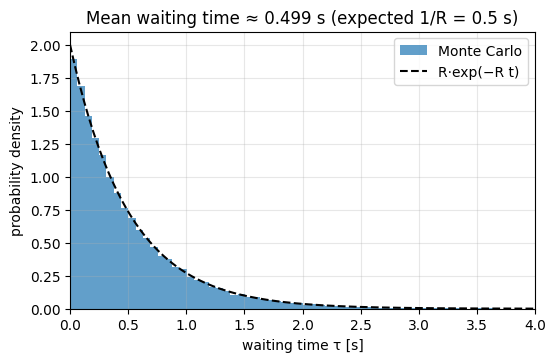

In [6]:
R = 2.0   # events per second
tau = [np.log(1/random.random()) / R for _ in range(50_000)]

t = np.linspace(0, 4, 200)
plt.hist(tau, bins=80, density=True, alpha=0.7, label="Monte Carlo")
plt.plot(t, R*np.exp(-R*t), "k--", label="R·exp(−R t)")
plt.xlim(0, 4); plt.xlabel("waiting time τ [s]"); plt.ylabel("probability density")
plt.title(f"Mean waiting time ≈ {np.mean(tau):.3f} s (expected 1/R = {1/R} s)"); plt.legend(); plt.show()

## 6 · Building a Monte Carlo decision tree: a molecule in a reactor with recycle
This last example is longer, and it is the most important one in the notebook. It has nothing to do with polymers, yet it uses **exactly** the structure of the steady state algorithms in the book: a chain of yes/no decisions, each with its own probability, and a loop that can repeat many times.

**The process.** A molecule of reactant A enters a reactor. On each pass:

| Node | Question | Probability |
|---|---|---|
| ① Reactor | Does A react on this pass? | `P_rxn = 0.30` |
| ② Selectivity | If it reacts, does it form the desired product B (or by-product C)? | `P_sel = 0.85` |
| ③ Product separator | Is B recovered (or lost to waste)? | `P_recB = 0.95` |
| ④ Recycle separator | If A did not react, is it recycled to the reactor (or purged)? | `P_rec = 0.90` |

Each molecule walks down the tree until it reaches an **end point** (a "leaf"): product B, B lost, by-product C, or A purged. A recycled molecule goes **back to node ①** — that's the loop.

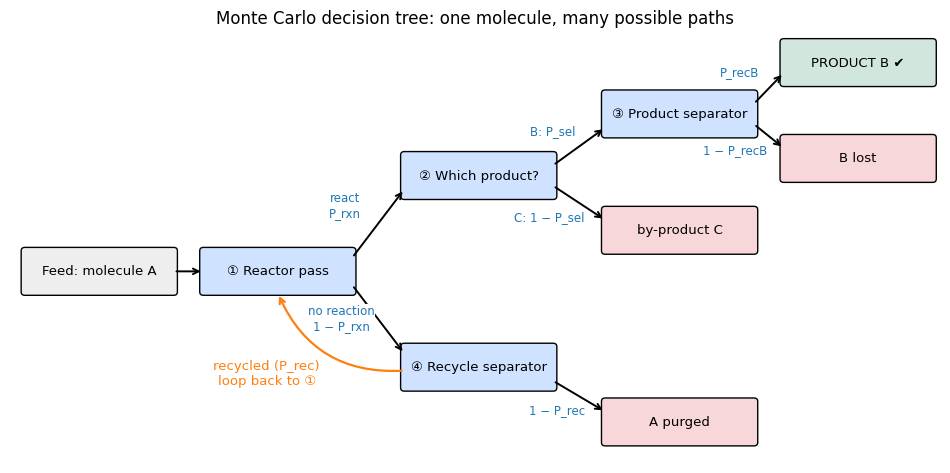

In [7]:
# Draw the decision tree
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.axis("off"); ax.set_xlim(-0.3, 12.2); ax.set_ylim(0.4, 6.7)
def box(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x-1.0, y-0.3), 2.0, 0.6, boxstyle="round,pad=0.05", fc=color, ec="k"))
    ax.text(x, y, text, ha="center", va="center", fontsize=9.5)
def arrow(x0, y0, x1, y1, label="", dx=0, dy=0.18, color="k"):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=1.4, color=color))
    if label:
        ax.text((x0+x1)/2 + dx, (y0+y1)/2 + dy, label, ha="center", fontsize=8.5, color="tab:blue",
                bbox=dict(fc="white", ec="none", pad=0.5))
box(0.9, 3.2, "Feed: molecule A", "#eeeeee")
box(3.3, 3.2, "① Reactor pass", "#cfe2ff")
box(6.0, 4.6, "② Which product?", "#cfe2ff")
box(6.0, 1.8, "④ Recycle separator", "#cfe2ff")
box(8.7, 5.5, "③ Product separator", "#cfe2ff")
box(8.7, 3.8, "by-product C", "#f8d7da")
box(8.7, 1.0, "A purged", "#f8d7da")
box(11.1, 6.25, "PRODUCT B ✔", "#d1e7dd")
box(11.1, 4.85, "B lost", "#f8d7da")
arrow(1.9, 3.2, 2.3, 3.2)
arrow(4.3, 3.4, 5.0, 4.4, "react\nP_rxn", dx=-0.45, dy=0.1)
arrow(4.3, 3.0, 5.0, 2.0, "no reaction\n1 − P_rxn", dx=-0.5, dy=-0.15)
arrow(7.0, 4.75, 7.7, 5.3, "B: P_sel", dx=-0.35)
arrow(7.0, 4.45, 7.7, 3.95, "C: 1 − P_sel", dx=-0.4, dy=-0.25)
arrow(9.7, 5.65, 10.1, 6.1, "P_recB", dx=-0.4)
arrow(9.7, 5.35, 10.1, 5.0, "1 − P_recB", dx=-0.45, dy=-0.25)
arrow(7.0, 1.6, 7.7, 1.15, "1 − P_rec", dx=-0.3, dy=-0.25)
ax.annotate("", (3.3, 2.88), (5.0, 1.75), arrowprops=dict(arrowstyle="->", lw=1.6, color="tab:orange",
            connectionstyle="arc3,rad=-0.35"))
ax.text(3.15, 1.55, "recycled (P_rec)\nloop back to ①", color="tab:orange", fontsize=9.5, ha="center")
ax.set_title("Monte Carlo decision tree: one molecule, many possible paths"); plt.show()

### 6.1 · One molecule, step by step
The code is a direct translation of the tree: one `if Rnd ≤ P` per node, and a `while` loop for the recycle. Run the cell a few times — every molecule takes its own path.

In [8]:
P_rxn, P_sel, P_recB, P_rec = 0.30, 0.85, 0.95, 0.90

def one_molecule(verbose=False):
    passes = 0
    while True:                                   # loop = recycle
        passes += 1
        say = print if verbose else (lambda *a: None)
        if random.random() <= P_rxn:              # node ① reacts?
            if random.random() <= P_sel:          # node ② desired product?
                if random.random() <= P_recB:     # node ③ recovered?
                    say(f"  pass {passes}: reacted → B → recovered ✔"); return "product B", passes
                say(f"  pass {passes}: reacted → B → lost"); return "B lost", passes
            say(f"  pass {passes}: reacted → by-product C"); return "by-product C", passes
        if random.random() <= P_rec:              # node ④ recycled?
            say(f"  pass {passes}: no reaction → recycled ↺")
            continue
        say(f"  pass {passes}: no reaction → purged"); return "A purged", passes

for k in range(1, 4):
    print(f"Molecule {k}:"); one_molecule(verbose=True)

Molecule 1:
  pass 1: no reaction → recycled ↺
  pass 2: reacted → B → recovered ✔
Molecule 2:
  pass 1: no reaction → purged
Molecule 3:
  pass 1: no reaction → recycled ↺
  pass 2: no reaction → recycled ↺
  pass 3: reacted → B → recovered ✔


### 6.2 · Many molecules → outcome distribution
Simulate 100,000 molecules and count where they end up (Trick #2). Because this tree is simple, we can also work out the exact answer by hand and check the code:
- probability of going around the loop once: `q = (1 − P_rxn)·P_rec`
- probability that the molecule eventually reacts: `P_rxn / (1 − q)`

product B      Monte Carlo = 0.6559   exact = 0.6547
B lost         Monte Carlo = 0.0336   exact = 0.0345
by-product C   Monte Carlo = 0.1208   exact = 0.1216
A purged       Monte Carlo = 0.1898   exact = 0.1892


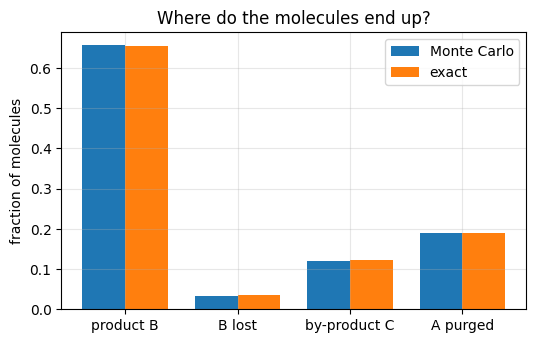

In [9]:
N = 100_000
results = [one_molecule() for _ in range(N)]
outcomes = ["product B", "B lost", "by-product C", "A purged"]
mc = np.array([sum(1 for o, _ in results if o == name) for name in outcomes]) / N

q = (1 - P_rxn) * P_rec
p_react = P_rxn / (1 - q)
exact = np.array([p_react*P_sel*P_recB, p_react*P_sel*(1-P_recB), p_react*(1-P_sel), (1-P_rxn)*(1-P_rec)/(1-q)])

for name, a, b in zip(outcomes, mc, exact):
    print(f"{name:13s}  Monte Carlo = {a:.4f}   exact = {b:.4f}")

w = 0.38; idx = np.arange(4)
plt.bar(idx - w/2, mc, w, label="Monte Carlo"); plt.bar(idx + w/2, exact, w, label="exact")
plt.xticks(idx, outcomes); plt.ylabel("fraction of molecules"); plt.legend(); plt.title("Where do the molecules end up?"); plt.show()

### 6.3 · How many passes? (this is a chain length distribution in disguise!)
Count the reactor passes each molecule made. Each extra pass happens with probability `q`, exactly like a chain adding one more monomer with probability `P_p`. The result is a **geometric distribution** — the same shape as the Flory distribution in Notebook 2.

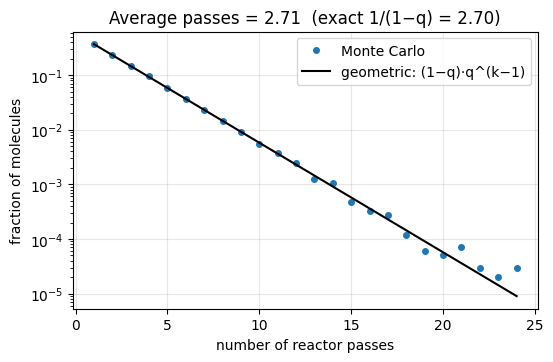

In [10]:
passes = np.array([p for _, p in results])
k = np.arange(1, passes.max() + 1)
counts = np.bincount(passes)[1:] / N
plt.semilogy(k, counts, "o", ms=4, label="Monte Carlo")
plt.semilogy(k, (1-q)*q**(k-1), "k-", label="geometric: (1−q)·q^(k−1)")
plt.xlabel("number of reactor passes"); plt.ylabel("fraction of molecules"); plt.legend()
plt.title(f"Average passes = {passes.mean():.2f}  (exact 1/(1−q) = {1/(1-q):.2f})"); plt.show()

### 6.4 · Use the model: how much recycle?
More recycle means fewer molecules are purged — but the extra passes also give A more chances to form the by-product C, and every pass adds load to the reactor. Monte Carlo lets us scan the design variable and see where all the molecules go.

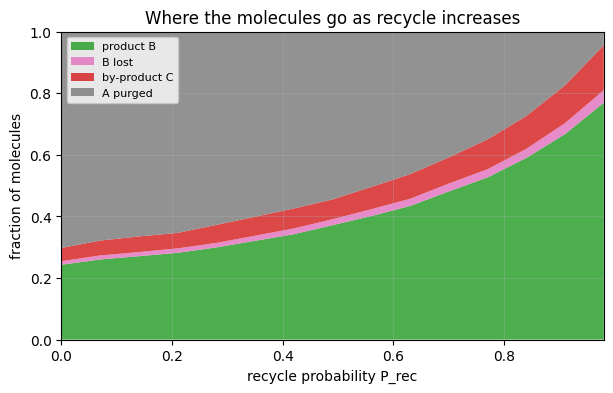

P_rec = 0.00: average reactor passes per molecule = 1.00
P_rec = 0.49: average reactor passes per molecule = 1.52
P_rec = 0.98: average reactor passes per molecule = 3.16


In [11]:
def outcome_fractions(P_rec_value, N=20_000):
    global P_rec
    P_rec = P_rec_value
    res = [one_molecule() for _ in range(N)]
    frac = [np.mean([o == name for o, _ in res]) for name in outcomes]
    return frac, np.mean([p for _, p in res])

recycle = np.linspace(0, 0.98, 15)
data = [outcome_fractions(r) for r in recycle]
fractions = np.array([d[0] for d in data]).T
P_rec = 0.90                                              # restore the base case

plt.figure(figsize=(7, 4))
plt.stackplot(recycle, fractions, labels=outcomes, colors=["tab:green", "tab:pink", "tab:red", "tab:gray"], alpha=0.85)
plt.xlabel("recycle probability P_rec"); plt.ylabel("fraction of molecules"); plt.xlim(0, 0.98); plt.ylim(0, 1)
plt.legend(loc="upper left", fontsize=8); plt.title("Where the molecules go as recycle increases"); plt.show()
for r, (_, avg) in zip(recycle[::7], data[::7]):
    print(f"P_rec = {r:.2f}: average reactor passes per molecule = {avg:.2f}")

### 6.5 · From this tree to a polymer chain
| Reactor with recycle | Steady state polymerization (book Ch. 3) |
|---|---|
| one molecule of A | one polymer radical (living chain) |
| one more reactor pass (`Rnd ≤ q`) | one more monomer added (`Rnd ≤ P_p`) |
| number of passes | chain length `n` |
| node ②: B or C? | which termination: combination or transfer? |
| node ③: recovered or lost? | which monomer re-initiates after transfer? |
| constant probabilities → simulate molecules one after another | constant probabilities → build chains one after another |

The probabilities here never change, which is what makes this a **steady state** model. If the reactor conditions drifted with time (feed running out, temperature changing), the probabilities would change too, and we would need a **dynamic** model — that's what Gillespie's method (Notebook 6) is for.

## ✅ Recap — your Monte Carlo toolbox
| Trick | Code | Used for |
|---|---|---|
| 1 · Does it happen? | `if random.random() <= P` | propagate or stop, which monomer adds, each node of a decision tree |
| 2 · Count to estimate | repeat N times, average | averages, distributions (error ~ 1/√N) |
| 3 · Which one happens? | cumulative sum + `Rnd × total` | choosing the next reaction |
| 4 · When? | `τ = ln(1/Rnd)/R` | the clock in kinetic Monte Carlo |

### 🧪 Try it yourself
1. Make the coin unfair (`P = 0.3`). How many flips until you are within 1 % of 0.3?
2. In the reactor example, add a fifth node: product B can decompose in the separator with probability 0.02. Where does it go in the tree? Update the code and the exact solution.
3. Simulate only 500 molecules several times. How much do the outcome fractions jump around?

➡️ **Next: Notebook 2 — Chain growth & molecular weight distributions**